# Sprint 2: features (tabular, text and visual)

**Parfois product similarity, MADSAD case study (FEP, University of Porto).**

Sprint 1 produced a clean table with one row per colourway (`outputs/phase1/items_clean.csv`). This notebook turns
each colourway into **numbers that can be compared**: one *block* of features per kind of information, so that
the similarity of two products can later be computed block by block and explained ("same family", "same
materials", "similar photo").

Every step that runs on a laptop is **written out here** with pandas, NumPy and Pillow. Two steps use large
pretrained neural networks; they were run once on one machine, their results saved in `data/embeddings/`, and
here they are **described and loaded**:

- the **text embedding** of each product description (sentence model all-MiniLM-L6-v2);
- the **image embedding** of each photo (CLIP ViT-B/32).

| Section | Block | How |
|---|---|---|
| 1 | — | Input and the common rule of every block |
| 2 | categorical | weighted one-hot of the product attributes |
| 3 | composition | materials, weighted by rarity |
| 4 | numeric | price within the category, launch date, season |
| 5 | — | filling missing material and metal, only where it is reliable |
| 6 | text | sentence embedding of a description (loaded) |
| 7 | image | CLIP embedding of the product crop (loaded) |
| 8 | palette | dominant colours of each photo (k-means in LAB) |
| 9 | — | colour names measured on the photos |
| 10 | — | the blocks side by side on one product |

The notebook writes no file. Running time: about 4 minutes (the palettes read every photo).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR, EMB_DIR = ROOT / "data" / "images", ROOT / "data" / "embeddings"
KEY = "PROD_CLR_EQUIV"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Input and the common rule

The input is the result of Sprint 1. Codes are read as text, so leading zeros survive.

In [2]:
CODES = {c: str for c in ["PROD_REF", "PROD_REF_EQUIV", "SEA_COD", "CAT_COD", "GFA_COD", "GFS_COD"]}
items = pd.read_csv(ROOT / "outputs" / "phase1" / "items_clean.csv", encoding="utf-8-sig", dtype=CODES, low_memory=False)
items["STORE_DATE_FINAL"] = pd.to_datetime(items["STORE_DATE_FINAL"])
for c in ["img_trusted", "img_colour_trusted"]:
    items[c] = items[c].astype(str).eq("True")
items = items.sort_values(KEY, kind="stable").reset_index(drop=True)
print(f"{len(items):,} colourways x {items.shape[1]} columns | photos trusted: {items['img_trusted'].sum():,}")
items[[KEY, "CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN", "CLR_DES", "FINISHING", "COMPOSITION", "PRICE_BASE_W_VAT"]].head()

10,555 colourways x 116 columns | photos trusted: 9,445


,PROD_CLR_EQUIV,CAT_DES_EN,GFA_DES_EN,GFS_DES_EN,CLR_DES,FINISHING,COMPOSITION,PRICE_BASE_W_VAT
0,1328502PM,Jewellery,Rings,Cocktail,Pastel Multicolor,Worn Gold,Stone; Zinc,8.99
1,140428_BN,Jewellery,Necklaces,Pendant,Silver,Other,NaN,9.99
2,1404862PE,Jewellery,Key chains,Figures,Pearl,Rodhium,Acrylic; Crystal Glass; Iron; Zinc,12.99
3,140486_BM,Jewellery,Key chains,Figures,Bright Multicolor,Golden,Acrylic; Crystal Glass; Iron; Zinc,12.99
4,140486_HM,Jewellery,Key chains,Figures,Halftone Multicolor,NaN,Crystal Glass; Iron; Zinc,9.99


**The rule every block follows.** Each product becomes a row of numbers of **length 1** (L2-normalised). The
similarity of two products in a block is then the dot product of their rows, the *cosine similarity*: 1 for
identical rows, 0 for nothing in common.

A block is also split into named **attributes** (groups of columns). The dot product of two rows is the sum of the
dot products of their attribute slices, so the score can be **explained**: e.g. 0.42 from the family, 0.20 from
the colour. A missing value is a row of zeros: it never counts as a match.

In [3]:
def normalise_rows(m):
    norms = np.linalg.norm(m, axis=1, keepdims=True)
    return np.divide(m, norms, out=np.zeros_like(m), where=norms > 0).astype(np.float32)

def shared_attributes(m, attrs, i, j):
    """How much each attribute adds to the similarity of rows i and j (the parts add up to the score)."""
    out = {}
    for name, (start, stop) in attrs.items():
        part = float(m[i, start:stop] @ m[j, start:stop])
        if part > 1e-6:
            out[name] = round(part, 3)
    return dict(sorted(out.items(), key=lambda kv: -kv[1]))

def neighbours(m, i, k=4, same_category=True):
    """Top k rows by cosine similarity: same category, other models only (another colour of the same model is
    trivially similar)."""
    s = m @ m[i]
    if same_category:
        s[(items["CAT_DES_EN"] != items["CAT_DES_EN"].iat[i]).to_numpy()] = -1
    s[(items["PROD_REF"] == items["PROD_REF"].iat[i]).to_numpy()] = -1
    top = np.argsort(-s, kind="stable")[:k]
    return top, s[top]

## 2. Categorical block

Each attribute is one-hot encoded, and each attribute gets a **weight** saying how much it matters for a buyer.
The value stored is √weight, so two products score the **sum of the weights they share** (before normalising).

Family (`GFA`) and sub-family (`GFS`) are encoded as **paths** (`Jewellery › Earrings › Hoop Earrings`), because names
such as "Others" repeat across categories and only mean something below their parent.

`FINISH_FAMILY` groups the ~30 finishing names into gold / rose gold / silver / black / other, so that "Golden" and
"Worn Gold" still get partial credit.

In [4]:
FINISH_FAMILY = {
    "gold": ["Golden", "Worn Gold", "Brushed Golden", "Antik Golden", "Gold Plated", "Matte Golden", "Burnish Golden",
             "Light Golden", "Worn Yellow Gold", "Matt Brushed Gold", "Scratched Gold"],
    "rose gold": ["Rose Gold", "Brushed Rose Gold", "Worn Rose God"],
    "silver": ["Rodhium", "Silver", "Worn Rhodium", "Worn Silver", "Brushed Silver", "Antik Silver", "Brushed Rhodium",
               "Matte Silver", "Silver Plated"],
    "black": ["Black Nikel", "Black Plating"],
    "other": ["Other", "Multifinishing", "Cooper"],
}
FAMILY_OF = {v: fam for fam, vals in FINISH_FAMILY.items() for v in vals}
items["FINISH_FAMILY"] = items["FINISHING"].map(FAMILY_OF)

# attribute -> (source columns forming a path, weight)
CATEGORICAL = {
    "CAT": (["CAT_DES_EN"], 1.0),
    "GFA": (["CAT_DES_EN", "GFA_DES_EN"], 3.0),
    "GFS": (["CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN"], 3.0),
    "CATEGORY_MATRIX": (["CATEGORY_MATRIX"], 1.5),
    "CLR_DES": (["CLR_DES"], 2.0),
    "CLR_TYPE": (["CLR_TYPE"], 0.5),
    "FINISHING": (["FINISHING"], 1.5),
    "FINISH_FAMILY": (["FINISH_FAMILY"], 1.0),
    "MATERIAL": (["MATERIAL"], 1.0),
    "PRINT_TYPE": (["PRINT_TYPE"], 1.0),
    "DIMENSION": (["DIMENSION"], 1.0),
    "OUTFIT": (["OUTFIT"], 1.0),
    "THEME": (["THEME"], 1.5),
    "FASHIONTYPE": (["FASHIONTYPE"], 0.5),
    "PROD_SEG": (["PROD_SEG"], 0.5),
    "NUMBER_OF_UNITS": (["NUMBER_OF_UNITS"], 0.5),
}

def categorical_block(df, spec=CATEGORICAL):
    parts, attrs, start = [], {}, 0
    for name, (cols, weight) in spec.items():
        values = df[cols[0]].astype("string")
        for c in cols[1:]:
            values = values + " › " + df[c].astype("string")       # missing if any part is missing
        levels = sorted(values.dropna().unique())
        codes = pd.Categorical(values, categories=levels).codes
        onehot = np.zeros((len(df), len(levels)), np.float32)
        onehot[np.flatnonzero(codes >= 0), codes[codes >= 0]] = np.sqrt(weight)
        parts.append(onehot)
        attrs[name] = (start, start + len(levels))
        start += len(levels)
    return normalise_rows(np.hstack(parts)), attrs

How filled and how varied each attribute is (before the missing values of section 5 are filled):

In [5]:
summary = pd.DataFrame({name: {"columns": " › ".join(cols), "weight": w,
                               "values": items[cols].dropna().drop_duplicates().shape[0],
                               "filled": items[cols].notna().all(axis=1).mean()}
                        for name, (cols, w) in CATEGORICAL.items()}).T
summary.style.format({"filled": "{:.0%}"})

,columns,weight,values,filled
CAT,CAT_DES_EN,1.000000,5,100%
GFA,CAT_DES_EN › GFA_DES_EN,3.000000,67,100%
GFS,CAT_DES_EN › GFA_DES_EN › GFS_DES_EN,3.000000,416,100%
CATEGORY_MATRIX,CATEGORY_MATRIX,1.500000,101,98%
CLR_DES,CLR_DES,2.000000,99,100%
CLR_TYPE,CLR_TYPE,0.500000,3,100%
FINISHING,FINISHING,1.500000,28,48%
FINISH_FAMILY,FINISH_FAMILY,1.000000,5,48%
MATERIAL,MATERIAL,1.000000,26,13%
PRINT_TYPE,PRINT_TYPE,1.000000,19,100%


## 3. Composition block

`COMPOSITION` lists the materials (`"Brass; Glass; Zinc"`). Each material is one column, weighted by its **rarity**
(IDF, as in text search): sharing "Pearl" says more than sharing "Polyester", which half the apparel has.

IDF = log((1 + N) / (1 + products with the material)) + 1

In [6]:
def composition_block(df):
    tokens = df["COMPOSITION"].fillna("").map(lambda s: sorted({t.strip() for t in str(s).split(";") if t.strip()}))
    vocab = sorted({t for ts in tokens for t in ts})
    col = {t: j for j, t in enumerate(vocab)}
    counts = pd.Series([t for ts in tokens for t in ts]).value_counts()
    idf = {t: float(np.log((1 + len(df)) / (1 + counts[t])) + 1) for t in vocab}
    m = np.zeros((len(df), len(vocab)), np.float32)
    for i, ts in enumerate(tokens):
        for t in ts:
            m[i, col[t]] = idf[t]
    return normalise_rows(m), {t: (j, j + 1) for t, j in col.items()}, counts, idf

comp, comp_attrs, counts, idf = composition_block(items)
print(f"{len(comp_attrs)} materials")
mat = pd.DataFrame({"products": counts, "weight (IDF)": pd.Series(idf).round(2)}).sort_values("products", ascending=False)
mat.iloc[list(range(6)) + list(range(-4, 0))]   # the most and the least common

95 materials


,products,weight (IDF)
Polyester,4312,1.90
Polyurethane,3273,2.17
Zinc,2444,2.46
Iron,2034,2.65
Thermoplastic Polyurethane,1194,3.18
Brass,1154,3.21
Pig leather,1,9.57
PROPIONIC ACID,1,9.57
Rattan,1,9.57
Vinyl,1,9.57


## 4. Numeric block

- **Price**, compared **within the category** (a 30 € bag is cheap, a 30 € ring is not): its percentile in the
  category, 0 to 1.
- **Launch date** (`STORE_DATE_FINAL`): months since the first launch.
- **Season** (`SEA_COD`): one-hot.

A number cannot simply be one column in a cosine similarity, so price and date are encoded as **soft bands**:
Gaussian bumps at regular centres. Two products then score about exp(−Δ² / 4σ²): close values ≈ 1, far values ≈ 0.
Weights inside the block: price 2, launch 1, season 0.5.

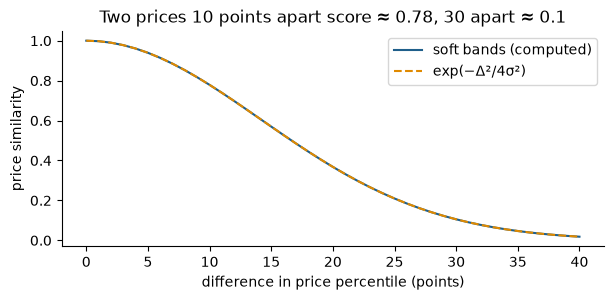

In [7]:
PRICE_SIGMA, LAUNCH_SIGMA = 0.10, 1.5          # in percentile points / in months
NUMERIC = {"price": 2.0, "launch": 1.0, "season": 0.5}

def soft_bands(x, centres, sigma):
    m = np.exp(-((x[:, None] - centres[None, :]) ** 2) / (2 * sigma ** 2)).astype(np.float32)
    m[np.isnan(x)] = 0
    return normalise_rows(m)

def numeric_block(df):
    price_pct = df.groupby("CAT_DES_EN")["PRICE_BASE_W_VAT"].rank(pct=True, method="average").to_numpy(float)
    months = ((df["STORE_DATE_FINAL"] - df["STORE_DATE_FINAL"].min()).dt.days / 30.44).to_numpy(float)
    # centres run 3σ past both ends, so values at the edges are compared like the others
    price_c = np.arange(-3 * PRICE_SIGMA, 1 + 3 * PRICE_SIGMA + 1e-9, PRICE_SIGMA / 2)
    launch_c = np.arange(np.floor(np.nanmin(months) - 3 * LAUNCH_SIGMA), np.ceil(np.nanmax(months) + 3 * LAUNCH_SIGMA) + 1e-9,
                         LAUNCH_SIGMA / 2)
    seasons = sorted(df["SEA_COD"].dropna().unique())
    codes = pd.Categorical(df["SEA_COD"], categories=seasons).codes
    season = np.zeros((len(df), len(seasons)), np.float32)
    season[np.flatnonzero(codes >= 0), codes[codes >= 0]] = 1
    parts = {"price": soft_bands(price_pct, price_c, PRICE_SIGMA), "launch": soft_bands(months, launch_c, LAUNCH_SIGMA),
             "season": season}
    attrs, start = {}, 0
    for name, m in parts.items():
        attrs[name] = (start, start + m.shape[1])
        start += m.shape[1]
    return normalise_rows(np.hstack([m * np.float32(np.sqrt(NUMERIC[n])) for n, m in parts.items()])), attrs

d = np.linspace(0, 0.4, 41)
centres = np.arange(-0.3, 1.3 + 1e-9, 0.05)
a = soft_bands(np.full(len(d), 0.5), centres, PRICE_SIGMA)
b = soft_bands(0.5 + d, centres, PRICE_SIGMA)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(d * 100, (a * b).sum(1), color="#1f5f8b", label="soft bands (computed)")
ax.plot(d * 100, np.exp(-d ** 2 / (4 * PRICE_SIGMA ** 2)), "--", color="#e08a00", label="exp(−Δ²/4σ²)")
ax.set_xlabel("difference in price percentile (points)")
ax.set_ylabel("price similarity")
ax.set_title("Two prices 10 points apart score ≈ 0.78, 30 apart ≈ 0.1")
ax.legend()
plt.show()

## 5. Filling missing material and metal, only where it is reliable

Two attributes buyers care about are often empty:

- `MATERIAL` (apparel only): the main fabric;
- the **metal** of jewellery (`FINISH_FAMILY`: gold, silver…).

They are filled **only for products with a trusted photo, and only when the guess is reliable**. The original values
are never replaced. Methods, in order:

1. **sibling** (material): another colour of the same model has a material (they agree 99.7% of the time);
2. **composition** (material): the composition is a single material that is also a `MATERIAL` value;
3. **neighbours**: a vote of the 15 most similar products of the category, weighted by similarity, kept when the
   winner has at least 80% of the votes. For the metal, the photo must agree: "gold" only if the colour palette is
   yellowish (mean b* ≥ 3), "silver" only if it is not (b* ≤ 6). Gold is 79% of the jewellery, so without this check
   silver items would too often be called gold.

Similarity for the vote: categorical block **without the attributes being guessed**, composition, CLIP image
embedding and colour palette (both loaded from `data/embeddings/`, see sections 7–8).

How reliable is each value? **5-fold cross-validation** on the products that do have it, with folds by model, so that
colours of the same model never help each other. A value is filled by the neighbours only if its precision is at least
90% on at least 10 predictions.

In [8]:
def aligned(npy, meta_json):
    keys = json.loads((EMB_DIR / meta_json).read_text(encoding="utf-8"))["keys"]
    emb = np.load(EMB_DIR / npy).astype(np.float32)
    idx = items[KEY].map(pd.Series(range(len(keys)), index=keys))
    out = np.zeros((len(items), emb.shape[1]), np.float32)
    ok = idx.notna().to_numpy()
    out[ok] = emb[idx[ok].astype(int).to_numpy()]
    return out

image_raw = aligned("image_clip.npy", "image_clip.json")
palettes_saved = pd.read_parquet(EMB_DIR / "palettes.parquet").set_index(KEY)
palette_raw = np.stack([np.asarray(v, np.float32) if isinstance(v, (list, np.ndarray)) else np.zeros(24, np.float32)
                        for v in items[KEY].map(palettes_saved["palette_vector"])])
image_raw[~items["img_trusted"].to_numpy()] = 0
palette_raw[~items["img_trusted"].to_numpy()] = 0
yellow = items[KEY].map(pd.Series([sum(s * c[2] for s, c in zip(sh, lab)) for sh, lab in
                                   zip(palettes_saved["shares"], palettes_saved["lab"])], index=palettes_saved.index)).to_numpy()

VOTE_WEIGHTS = {"MATERIAL": {"categorical": 1.0, "composition": 3.0, "image": 1.0, "palette": 0.5},
                "FINISH_FAMILY": {"categorical": 1.0, "composition": 1.0, "image": 2.0, "palette": 2.0}}

def vote_features(target):
    spec = {k: v for k, v in CATEGORICAL.items() if k not in ("FINISHING", "MATERIAL", "FINISH_FAMILY")}
    parts = {"categorical": categorical_block(items, spec)[0], "composition": comp, "image": image_raw, "palette": palette_raw}
    w = VOTE_WEIGHTS[target]
    return normalise_rows(np.hstack([m * np.float32(np.sqrt(w[n])) for n, m in parts.items()]))

def knn_vote(Xq, Xt, yt, k=15):
    pred, conf = np.empty(len(Xq), dtype=object), np.zeros(len(Xq))
    for s in range(0, len(Xq), 512):
        sim = Xq[s:s + 512] @ Xt.T
        top = np.argsort(-sim, axis=1, kind="stable")[:, :k]
        for i, row in enumerate(top):
            votes = pd.Series(np.clip(sim[i, row], 0, None)).groupby(yt[row]).sum()
            if votes.sum() > 0:
                best = votes.sort_index().idxmax()
                pred[s + i], conf[s + i] = best, votes[best] / votes.sum()
    return pred, conf

def photo_agrees(pred, yel):
    pred, yel = np.asarray(pred, dtype=object), np.asarray(yel, float)
    return ~(((pred == "gold") & ~(yel >= 3.0)) | ((pred == "silver") & (yel > 6.0)))

In [9]:
TARGETS = {"MATERIAL": "Apparel", "FINISH_FAMILY": "Jewellery"}
filled, evidence = [], {}
for col, cat in TARGETS.items():
    X = vote_features(col)
    in_cat = items["CAT_DES_EN"].eq(cat)
    lab = (in_cat & items[col].notna()).to_numpy()
    y, groups = items.loc[lab, col].to_numpy(), items.loc[lab, "PROD_REF"].to_numpy()

    # cross-validation, folds by model
    rng = np.random.default_rng(0)
    models = np.unique(groups)
    fold = pd.Series(rng.integers(0, 5, len(models)), index=models).loc[groups].to_numpy()
    pred, conf = np.empty(len(y), dtype=object), np.zeros(len(y))
    for f in range(5):
        pred[fold == f], conf[fold == f] = knn_vote(X[lab][fold == f], X[lab][fold != f], y[fold != f])
    ok_photo = photo_agrees(pred, yellow[lab]) if col == "FINISH_FAMILY" else np.ones(len(y), bool)
    kept = (conf >= 0.8) & ok_photo
    prec = pd.Series(pred[kept] == y[kept]).groupby(pred[kept]).agg(["mean", "size"])
    allowed = set(prec.index[(prec["mean"] >= 0.9) & (prec["size"] >= 10)])
    evidence[col] = {"products with the value": len(y), "accuracy (all)": (pred == y).mean(),
                     "share kept (vote ≥ 80%)": kept.mean(), "accuracy (kept)": (pred == y)[kept].mean(),
                     "values allowed": ", ".join(sorted(allowed))}

    # fill: trusted photo, value missing
    todo = in_cat & items[col].isna() & items["img_trusted"]
    guess = pd.Series(np.nan, index=items.index[todo], dtype=object)
    method = pd.Series("", index=guess.index)
    if col == "MATERIAL":
        vocab = set(items.loc[in_cat, col].dropna())
        sib = items[items[col].notna()].groupby("PROD_REF")[col].agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan)
        single = items["COMPOSITION"].fillna("").map(
            lambda s: [t.strip() for t in s.split(";") if t.strip()]).map(lambda t: t[0] if len(t) == 1 and t[0] in vocab else np.nan)
        for name, values in (("sibling", items["PROD_REF"].map(sib)), ("composition", single)):
            free = guess.isna() & values.loc[guess.index].notna()
            guess[free], method[free] = values.loc[guess.index[free]], name
    free = guess.index[guess.isna()]
    p, c = knn_vote(X[free.to_numpy()], X[lab], y)
    keep = (c >= 0.8) & np.isin(p, list(allowed))
    if col == "FINISH_FAMILY":
        keep &= photo_agrees(p, yellow[free.to_numpy()])
    guess[free[keep]], method[free[keep]] = p[keep], "neighbours"
    done = guess.notna()
    filled.append(pd.DataFrame({KEY: items.loc[guess.index[done], KEY], "column": col, "value": guess[done],
                                "method": method[done]}))
filled = pd.concat(filled, ignore_index=True)
pd.DataFrame(evidence).T

,products with the value,accuracy (all),share kept (vote ≥ 80%),accuracy (kept),values allowed
MATERIAL,1303,0.785879,0.655411,0.923888,"Cotton, Lyocell, Polyester, Viscose"
FINISH_FAMILY,4154,0.866875,0.616273,0.965234,"gold, other, silver"


In [10]:
print(filled.groupby(["column", "method"]).size().rename("values filled").to_string())
for col in TARGETS:
    sub = filled[filled["column"] == col].set_index(KEY)["value"]
    items[col] = items[col].where(items[col].notna(), items[KEY].map(sub))
print("\nfilled now:", {col: f"{items.loc[items['CAT_DES_EN'] == cat, col].notna().mean():.0%} of {cat}"
                        for col, cat in TARGETS.items()})

column         method     
FINISH_FAMILY  neighbours     266
MATERIAL       composition    324
               neighbours     195
               sibling         61

filled now: {'MATERIAL': '83% of Apparel', 'FINISH_FAMILY': '95% of Jewellery'}


Not filled on purpose: the detailed finishing (golden vs worn gold vs brushed golden…) and the finishing of hand
bags, because the neighbours get them right too rarely.

With the filled values, the three tabular blocks are built:

In [11]:
cat_m, cat_attrs = categorical_block(items)
num_m, num_attrs = numeric_block(items)
print(f"categorical {cat_m.shape} | composition {comp.shape} | numeric {num_m.shape}")

categorical (10555, 1624) | composition (10555, 95) | numeric (10555, 79)


## 6. Text block (computed once, loaded here)

The categorical block only matches **identical** labels: "Golden Basics" and "GOLDEN DELICATES", or "Hoop Earrings" and
"Huggie", count as different. A sentence model knows they are close.

For each product a short English description is **built from the reviewed attributes** (never from the photo):

In [12]:
def clean(v):
    return "" if pd.isna(v) else str(v).strip()

def describe(r):
    theme = clean(r["THEME"])
    theme = theme.title() if theme.isupper() else theme
    finish = f"Finish: {clean(r['FINISHING'])}. " if clean(r["FINISHING"]) else ""
    material = f"Made of {clean(r['COMPOSITION']).replace(';', ',')}. " if clean(r["COMPOSITION"]) else ""
    prt = f"Print: {clean(r['PRINT_TYPE'])}. " if clean(r["PRINT_TYPE"]) not in ("", "No Print") else ""
    return (f"{clean(r['GFS_DES_EN'])} ({clean(r['GFA_DES_EN'])}, {clean(r['CAT_DES_EN'])}). "
            f"Colour: {clean(r['CLR_DES']) or 'unknown'}. {finish}{material}{prt}Theme: {theme or 'none'}. "
            f"{clean(r['FASHIONTYPE'])}, {clean(r['PROD_SEG'])}.").strip()

text_meta = json.loads((EMB_DIR / "text.json").read_text(encoding="utf-8"))
for d in items.head(3).apply(describe, axis=1):
    print("•", d)

• Cocktail (Rings, Jewellery). Colour: Pastel Multicolor. Finish: Worn Gold. Made of Stone, Zinc. Theme: Nile. Fashion, Woman.
• Pendant (Necklaces, Jewellery). Colour: Silver. Finish: Other. Theme: Silver Provision. Fashion, Woman.
• Figures (Key chains, Jewellery). Colour: Pearl. Finish: Rodhium. Made of Acrylic, Crystal Glass, Iron, Zinc. Theme: Fashion Supplements. Fashion, Woman.


These sentences were encoded **once** with the sentence model `all-MiniLM-L6-v2` (about 1 minute on a CPU): each
becomes 384 numbers, the average of the model's token vectors, normalised to length 1. Products described in similar
words get close vectors. The result is loaded:

In [13]:
text_m = normalise_rows(aligned("text.npy", "text.json"))
print(f"model: {text_meta['model']} | {text_meta['n']:,} products x {text_meta['dim']} numbers")
print("saved description of the first product:", text_meta["examples"][0])

model: sentence-transformers/all-MiniLM-L6-v2 | 10,555 products x 384 numbers
saved description of the first product: Cocktail (Rings, Jewellery). Colour: Pastel Multicolor. Finish: Worn Gold. Made of Stone, Zinc. Theme: Nile. Fashion, Woman.


## 7. Image block (computed once, loaded here)

The photos carry what the table cannot: shape, style, texture. In Sprint 1 every photo was processed once:

1. the **product is isolated**: the white background is cropped, and for photos with a model or a scene an object
   detector (OWLv2) finds the item, so a model's face or clothes do not drive the similarity;
2. the crop is encoded with **CLIP ViT-B/32**, a network trained on 400 million image–caption pairs: 512 numbers per
   photo, normalised to length 1.

Only photos the review **trusted** feed the block (`img_trusted`); the others are rows of zeros, so a wrong photo can
never make two products similar.

9,445 trusted photos x 512 numbers


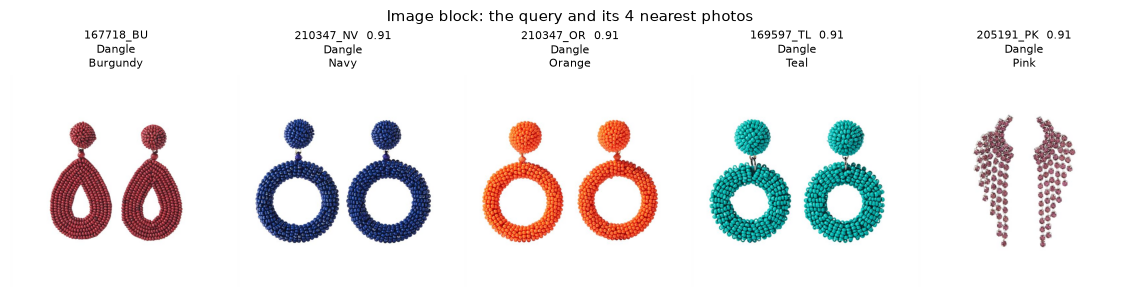

In [14]:
image_m = normalise_rows(image_raw)
print(f"{(np.abs(image_m).sum(1) > 0).sum():,} trusted photos x {image_m.shape[1]} numbers")

def show(keys, title, scores=None):
    rows = items.set_index(KEY).loc[list(keys)]
    fig, axes = plt.subplots(1, len(rows), figsize=(2.3 * len(rows), 2.9))
    for n, (ax, (k, r)) in enumerate(zip(np.atleast_1d(axes), rows.iterrows())):
        if r["img_trusted"]:
            ax.imshow(Image.open(IMG_DIR / r["img_file"]).convert("RGB"))
        else:
            ax.text(0.5, 0.5, "no trusted photo", ha="center", color="#999")
        extra = "" if scores is None or n == 0 else f"  {scores[n - 1]:.2f}"
        ax.set_title(f"{k}{extra}\n{r['GFS_DES_EN']}\n{r['CLR_DES']}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

q = items.index[items[KEY] == "167718_BU"][0]            # the example of the brief
top, s = neighbours(image_m, q)
show([items[KEY].iat[q]] + items[KEY].iloc[top].tolist(), "Image block: the query and its 4 nearest photos", s)

## 8. Colour palette block

CLIP sees shape and style more than exact colours, and the colour *name* in the data is broad ("Blue" for navy and
turquoise alike). So each trusted photo also gets its **dominant colours**, measured on the pixels:

1. keep the **product pixels**: inside the product box found in Sprint 1, without the near-white background, resized
   to at most 96 px;
2. convert them to **CIELAB**, a colour space where distances match what the eye sees;
3. **k-means** with 4 clusters (k-means++ start, fixed seed): each cluster centre is a dominant colour, its size the
   colour's share; clusters under 5% are dropped;
4. **name** each colour after the nearest of 24 reference colours;
5. the **palette vector**: the shares summed per colour name, normalised. Two products both "mostly gold and white"
   get a high dot product.

In [15]:
NAMED = {
    "black": (25, 25, 25), "white": (245, 245, 242), "grey": (128, 128, 128), "silver": (190, 190, 195),
    "gold": (205, 170, 90), "beige": (222, 203, 170), "camel": (190, 140, 85), "brown": (110, 70, 40),
    "red": (200, 35, 40), "burgundy": (115, 25, 45), "pink": (240, 150, 175), "fuchsia": (215, 45, 140),
    "orange": (240, 130, 45), "yellow": (245, 215, 55), "green": (45, 150, 75), "khaki": (120, 120, 65),
    "mint": (165, 220, 190), "teal": (10, 120, 120), "turquoise": (60, 195, 200), "light blue": (155, 195, 230),
    "blue": (45, 85, 190), "navy": (28, 38, 80), "purple": (110, 55, 150), "lilac": (190, 165, 220),
}
NAMES = list(NAMED)

def rgb_to_lab(rgb):
    c = np.asarray(rgb, dtype=np.float64) / 255.0
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    m = np.array([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750], [0.0193339, 0.1191920, 0.9503041]])
    xyz = c @ m.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > (6 / 29) ** 3, np.cbrt(xyz), xyz / (3 * (6 / 29) ** 2) + 4 / 29)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

NAMED_LAB = rgb_to_lab(np.array(list(NAMED.values())))

def kmeans(x, k, iters=20, seed=0):
    rng = np.random.default_rng(seed)
    k = min(k, len(np.unique(x, axis=0)))
    centres = [x[rng.integers(len(x))]]
    for _ in range(1, k):                                   # k-means++: spread the starting centres
        d = np.min(((x[:, None] - np.array(centres)[None]) ** 2).sum(-1), axis=1)
        centres.append(x[rng.choice(len(x), p=d / d.sum())])
    c = np.array(centres)
    for _ in range(iters):
        labels = ((x[:, None] - c[None]) ** 2).sum(-1).argmin(1)
        new = np.array([x[labels == j].mean(0) if (labels == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c):
            break
        c = new
    return c, ((x[:, None] - c[None]) ** 2).sum(-1).argmin(1)

def product_pixels(img, box):
    img = img.convert("RGB")
    if box is not None and len(box) == 4:
        w, h = img.size
        x0, y0, x1, y1 = box
        img = img.crop((int(x0 * w), int(y0 * h), max(int(x0 * w) + 1, int(x1 * w)), max(int(y0 * h) + 1, int(y1 * h))))
    img.thumbnail((96, 96))
    a = np.asarray(img, dtype=np.uint8).reshape(-1, 3)
    keep = a.min(1) < 235                                    # near-white = background
    return a[keep] if keep.mean() > 0.02 else a              # an all-white product would vanish: keep the box

def palette(pixels, k=4):
    lab = rgb_to_lab(pixels)
    centres, labels = kmeans(lab, k)
    share = np.bincount(labels, minlength=len(centres)) / len(labels)
    keep = share >= 0.05
    centres, share = centres[keep], share[keep] / share[keep].sum()
    rgb = np.array([pixels[labels == j].mean(0) for j in np.flatnonzero(keep)])
    names = np.array(NAMES)[((centres[:, None, :] - NAMED_LAB[None]) ** 2).sum(-1).argmin(1)]
    order = np.argsort(-share, kind="stable")
    return [{"lab": centres[j], "rgb": rgb[j] / 255, "share": float(share[j]), "name": str(names[j])} for j in order]

def palette_vector(entries):
    v = np.zeros(len(NAMES), np.float32)
    for e in entries:
        v[NAMES.index(e["name"])] += e["share"]
    return v / np.linalg.norm(v) if np.linalg.norm(v) > 0 else v

In [16]:
masks = pd.read_parquet(EMB_DIR / "masks.parquet").set_index(KEY)
todo = items[items["img_trusted"]]
pal, pal_vec = {}, np.zeros((len(items), len(NAMES)), np.float32)
for i, r in todo.iterrows():                                  # every trusted photo, about 2.5 minutes
    box = masks["box"].get(r[KEY])
    box = None if box is None or (isinstance(box, float) and np.isnan(box)) else list(box)
    with Image.open(IMG_DIR / r["img_file"]) as img:
        pal[r[KEY]] = palette(product_pixels(img, box))
    pal_vec[i] = palette_vector(pal[r[KEY]])
palette_m = normalise_rows(pal_vec)
print(f"palettes: {len(pal):,} photos | colours per photo:",
      pd.Series([len(p) for p in pal.values()]).value_counts().sort_index().to_dict())

palettes: 9,445 photos | colours per photo: {1: 460, 2: 1303, 3: 2208, 4: 5474}


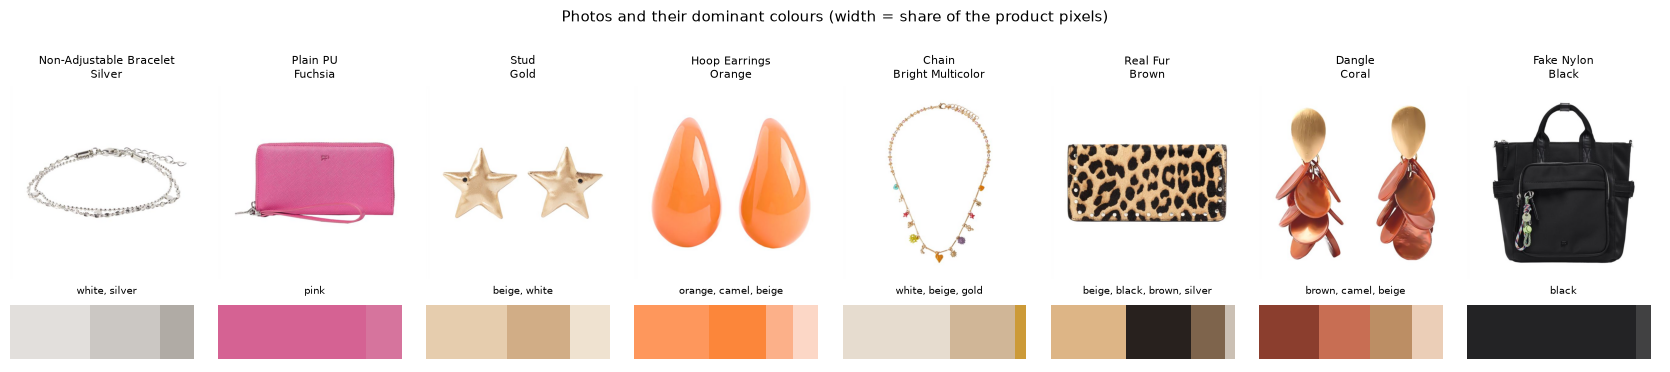

In [17]:
sample = todo[KEY].sample(8, random_state=1).tolist()
fig, axes = plt.subplots(2, len(sample), figsize=(2.1 * len(sample), 3.6), gridspec_kw={"height_ratios": [4, 1]})
for n, k in enumerate(sample):
    r = items.set_index(KEY).loc[k]
    axes[0, n].imshow(Image.open(IMG_DIR / r["img_file"]).convert("RGB"))
    axes[0, n].set_title(f"{r['GFS_DES_EN']}\n{r['CLR_DES']}", fontsize=8)
    x = 0
    for e in pal[k]:
        axes[1, n].barh(0, e["share"], left=x, color=e["rgb"])
        x += e["share"]
    axes[1, n].set_title(", ".join(dict.fromkeys(e["name"] for e in pal[k])), fontsize=7)
    for ax in axes[:, n]:
        ax.axis("off")
fig.suptitle("Photos and their dominant colours (width = share of the product pixels)", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

**Metals look like light neutrals.** On a packshot the largest cluster of a gold item is its highlights: light and
barely saturated, the same as beige or ecru; silver looks white or grey. So the palette does not tell the metal; the
metal comes from `FINISHING`. Palette *similarity* still works, because two gold items get the same palette.

## 9. Colour names measured on the photos

The data has about 100 colour names, many of them shades of one colour ("Navy", "Midnight Blue", "Blue"). As a one-hot
they are as different as "Blue" and "Red". Here each name gets a **reference colour measured on the photos**: the median
LAB of the dominant palette colour of the packshots with that name (at least 5 photos). Two names are then compared by
their distance in LAB, with lightness counting half (a lighter shade of a colour is still that colour):
similarity = exp(−d² / 2τ²), τ = 8.

Multicolour and metallic names get no reference (one colour means nothing for a print, and gold measures as beige).
This table is used later to **explain** matches ("Navy ≈ Midnight Blue"); it is not a score block, because a soft
colour match in the categorical block changed none of the evaluation numbers.

In [18]:
METALLIC = {"Gold", "Light Gold", "Old Gold", "Rose Gold", "Silver", "Old Silver", "Nickel", "Black Nickel", "Copper", "Bronze"}
packshot = masks["packshot"].reindex(items[KEY]).fillna(False).to_numpy(bool)
use = items["img_colour_trusted"].to_numpy() & packshot & items[KEY].isin(pal).to_numpy()
dom = np.stack([pal[k][0]["lab"] for k in items.loc[use, KEY]])     # the largest colour of each photo
ref = pd.DataFrame(dom, columns=["L", "a", "b"]).groupby(items.loc[use, "CLR_DES"].to_numpy()).median()
ref["photos"] = items.loc[use, "CLR_DES"].value_counts()
ref = ref[(ref["photos"] >= 5) & ~ref.index.str.lower().str.contains("multicolor") & ~ref.index.isin(METALLIC)]

lab = ref[["L", "a", "b"]].to_numpy() * np.array([0.5, 1, 1])
sim = np.exp(-((lab[:, None] - lab[None]) ** 2).sum(-1) / (2 * 8.0 ** 2))
names = ref.index.to_numpy()
close = {n: ", ".join(f"{names[j]} {sim[i, j]:.2f}" for j in np.argsort(-sim[i], kind="stable") if j != i and sim[i, j] >= 0.3)
         for i, n in enumerate(names)}
print(f"{len(ref)} colour names with a measured reference colour")
pd.DataFrame({"photos": ref["photos"], "closest names": pd.Series(close)}).loc[
    lambda d: d.index.isin(["Navy", "Blue", "Turquoise", "Beige", "Ecru", "Burgundy", "Khaki", "Pink"])]

64 colour names with a measured reference colour


,photos,closest names
Beige,212,"Skin 0.85, Pearl 0.78, Ecru 0.77, Nude 0.70, I..."
Blue,343,"Blue Jeans 0.87, Indigo 0.38, Light Blue 0.33"
Burgundy,147,"Wine 0.77, Aubergine 0.64"
Ecru,515,"Pearl 0.98, Ivory 0.97, Off White 0.93, Skin 0..."
Khaki,262,"Forest Green 0.92, Brown 0.53, Dark Green 0.43..."
Navy,127,"Midnight Blue 0.87, Dark Grey 0.74, Anthracite..."
Pink,154,Mauve 0.33
Turquoise,62,Aquamarine 0.79


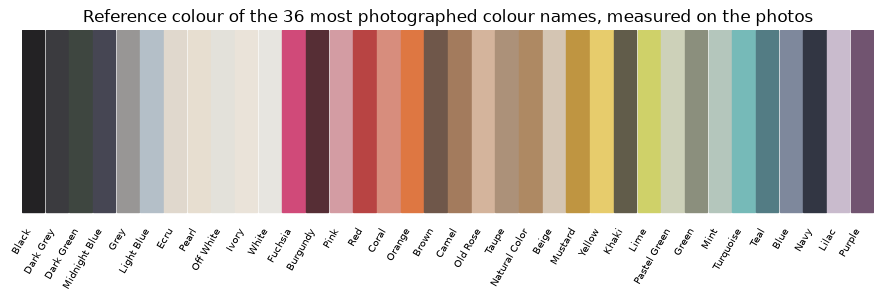

In [19]:
def lab_to_rgb(L, a, b):
    fy = (L + 16) / 116
    f = np.array([fy + a / 500, fy, fy - b / 200])
    xyz = np.where(f > 6 / 29, f ** 3, 3 * (6 / 29) ** 2 * (f - 4 / 29)) * np.array([0.95047, 1.0, 1.08883])
    m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660, 1.8760108, 0.0415560], [0.0556434, -0.2040259, 1.0572252]])
    c = np.clip(m @ xyz, 0, 1)
    return np.where(c > 0.0031308, 1.055 * c ** (1 / 2.4) - 0.055, 12.92 * c)

top = ref.sort_values("photos", ascending=False).head(36)
chroma = np.hypot(top["a"], top["b"])
top = top.assign(order=np.where(chroma < 8, -1000 + top["L"], np.degrees(np.arctan2(top["b"], top["a"])) % 360)).sort_values("order")  # neutrals first, then by hue
fig, ax = plt.subplots(figsize=(11, 2.6))
for n, (name, r) in enumerate(top.iterrows()):
    ax.add_patch(plt.Rectangle((n, 0), 0.95, 1, color=lab_to_rgb(r.L, r.a, r.b)))
    ax.text(n + 0.47, -0.08, name, rotation=60, ha="right", va="top", fontsize=7)
ax.set_xlim(0, len(top))
ax.set_ylim(-0.1, 1)
ax.axis("off")
ax.set_title("Reference colour of the 36 most photographed colour names, measured on the photos")
plt.show()

## 10. The blocks side by side

Six blocks, one per kind of information, all with the same rules (rows of length 1, missing = zeros):

In [20]:
blocks = {"categorical": cat_m, "composition": comp, "numeric": num_m, "text": text_m, "image": image_m, "palette": palette_m}
pd.DataFrame({name: {"numbers per product": m.shape[1], "products with the block": int((np.abs(m).sum(1) > 0).sum()),
                     "share": (np.abs(m).sum(1) > 0).mean()} for name, m in blocks.items()}).T.style.format({"share": "{:.1%}"})

,numbers per product,products with the block,share
categorical,1624.000000,10555.000000,100.0%
composition,95.000000,10554.000000,100.0%
numeric,79.000000,10555.000000,100.0%
text,384.000000,10555.000000,100.0%
image,512.000000,9445.000000,89.5%
palette,24.000000,9445.000000,89.5%


Each block finds **different** neighbours for the same product, which is why they are combined. For the example of the
brief, the best match of each block, and *why* (the attributes behind the categorical score):

In [21]:
rows = []
for name, m in blocks.items():
    top, s = neighbours(m, q, k=1)
    j = top[0]
    rows.append({"block": name, "best match": items[KEY].iat[j], "score": round(float(s[0]), 2),
                 "sub-family": items["GFS_DES_EN"].iat[j], "colour": items["CLR_DES"].iat[j],
                 "price": items["PRICE_BASE_W_VAT"].iat[j]})
r = items.iloc[q]
print(f"query {r[KEY]}: {r['GFS_DES_EN']}, {r['CLR_DES']}, {r['FINISHING']}, {r['PRICE_BASE_W_VAT']} €")
pd.DataFrame(rows).set_index("block")

query 167718_BU: Dangle, Burgundy, Golden, 8.99 €


,best match,score,sub-family,colour,price
block,,,,,
categorical,210347_NV,0.89,Dangle,Navy,8.99
composition,169607_IG,1.00,Dangle,Indigo,8.99
numeric,203374_NV,1.00,Stud,Navy,8.99
text,210295_BU,0.99,Dangle,Burgundy,5.99
image,210347_NV,0.91,Dangle,Navy,8.99
palette,209725_BU,1.00,Fan,Burgundy,12.99


In [22]:
top, s = neighbours(cat_m, q, k=4)
for j, score in zip(top, s):
    print(f"{items[KEY].iat[j]}  score {score:.2f}  =", shared_attributes(cat_m, cat_attrs, q, j))

210347_NV  score 0.89  = {'GFA': 0.162, 'GFS': 0.162, 'CATEGORY_MATRIX': 0.081, 'FINISHING': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'FINISH_FAMILY': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
1713311BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
214234_BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
215109_BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027,

The categorical score of each neighbour is the sum of the attributes they share: this is how the final system will
**explain** a match. Sprint 3 combines the six blocks into one score (a weighted sum, with weights tuned on evaluation
data and on the team's own judgement).

## Summary

| Block | What it captures | Built |
|---|---|---|
| categorical | family, sub-family, colour name, finishing, theme, … (16 weighted attributes) | here |
| composition | materials, rare ones counting more | here |
| numeric | price within the category, launch date, season | here |
| text | the description's meaning ("Golden Basics" ≈ "Golden Delicates") | sentence model, once |
| image | shape and style of the product crop | CLIP, once |
| palette | the dominant colours of the photo | here (k-means in LAB) |

Also: missing material (apparel) and metal (jewellery) filled only where 5-fold cross-validation shows ≥ 90% precision,
and a reference colour per colour name, measured on the photos, for the explanations.